# XP Exercises: Flower Classification using CNN

This is a guided notebook for the exercises on the platform. Cells marked **PREFILLED** are for execution only. Cells marked **To-Do** require your action. When a written answer is required, the **To-Do** appears inside a markdown cell. When code is required, the **To-Do** appears inside a code cell as comments.

Learning points appear only for key concepts that unlock intuition or transfer to other ML topics.


## What you will learn
- Building a CNN for multi class image classification
- Data loading and preprocessing with `image_dataset_from_directory`
- Image visualization techniques
- Model architecture design, compilation, and training
- Evaluating model performance with accuracy and loss plots


## What you will create
A CNN model that classifies 14 flower species.
All parts form one continuous exercise. Work through them sequentially.


## Dataset
**As stated in the exercises**  
Flower classification with 14 classes. Images are organized in class folders. A training and validation split may be provided. Images are resized to 256x256 in this notebook.

**PREFILLED info**  
This notebook expects the provided zip file to be available. The code below extracts it and locates the dataset root automatically.


## How I run this notebook
I open it in [Google Colab](https://colab.research.google.com) (**File → Upload notebook**) and run the cells from top to bottom. The cell below downloads the dataset zip from the course GitHub, so I don't have to upload anything. I fix the random seeds, so my numbers can be repeated (CPU and GPU can still differ a little).

Everything here was trained on a CPU, so I kept the image size small (64x64) and the number of epochs modest.

In [1]:
# download the dataset zip next to the notebook (skipped if it is already there)
import os, urllib.request

ZIP_URL = "https://github.com/devtlv/Datasets-GEN-AI-Bootcamp/raw/refs/heads/main/Week%206/W6D3/Flower%20Classification.zip"
ZIP_NAME = "Flower Classification.zip"   # the name the PREFILLED cell expects

if not os.path.exists(ZIP_NAME):
    urllib.request.urlretrieve(ZIP_URL, ZIP_NAME)
print(ZIP_NAME, round(os.path.getsize(ZIP_NAME) / 1e6, 1), "MB")

Flower Classification.zip 214.8 MB


In [2]:
# PREFILLED: just execute
import os, sys, zipfile, shutil, glob, math, json, random
from pathlib import Path

DATA_ZIP = Path("./Flower Classification.zip")
EXTRACT_DIR = Path("./data/flower_data")

# Clean extract dir if re-running
if EXTRACT_DIR.exists():
    pass  # avoid deleting in case you added files; delete manually if needed
else:
    EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

# Extract if a zip is present and not already extracted
if DATA_ZIP.exists():
    # Heuristically decide to extract once
    marker = EXTRACT_DIR / ".extracted"
    if not marker.exists():
        with zipfile.ZipFile(DATA_ZIP, 'r') as zf:
            zf.extractall(EXTRACT_DIR)
        marker.write_text("ok")
        print("Extracted:", DATA_ZIP.name, "->", EXTRACT_DIR)
    else:
        print("Already extracted. Skipping.")
else:
    print("Zip file not found at", DATA_ZIP)

# Find candidate dataset roots: a dir with >= 10 subdirs assumed as classes, or contains train/val
def list_dirs(p):
    return [d for d in Path(p).iterdir() if d.is_dir()]

candidates = []
for root, dirs, files in os.walk(EXTRACT_DIR):
    if len([d for d in Path(root).iterdir() if Path(d).is_dir()]) >= 10:
        candidates.append(Path(root))
    if "train" in [d.name.lower() for d in list_dirs(root)] and "val" in [d.name.lower() for d in list_dirs(root)]:
        candidates.append(Path(root))

candidates = sorted(set(candidates))
print("Candidate dataset roots:", [str(c) for c in candidates][:5])

Extracted: Flower Classification.zip -> data/flower_data
Candidate dataset roots: ['data/flower_data/Data', 'data/flower_data/Data/train', 'data/flower_data/Data/val']


## Part 1. Data exploration and visualization

**As stated in the exercises**  
Load the dataset using `image_dataset_from_directory`. Print number of images per class. Modify `visualize_images` to show a 3x3 grid for each class with the class name as the grid title. Analyze challenges you anticipate when classifying the flowers such as similar colors or shapes and intra class variation.


**Guidance**  
If a `train` or `val` folder exists, use them. Otherwise create a split from a single root with `validation_split` and `subset`. Images are resized to 256x256 RGB.


> **IMPORTANT:** we fix a low resultion for images in IMG_SIZE=(32,32) for faster training, however you can change it if you want to test out other resolutions

**What this cell does (PREFILLED):** sets the image size, batch size and seed, and checks whether the zip already has a `train`/`val` split. I only changed `IMG_SIZE` to 64x64, as the note above allows.

In [3]:
# PREFILLED: just execute
import tensorflow as tf
from tensorflow.keras import layers

IMG_SIZE = (64, 64)   # I changed 32x32 to 64x64: still fast on CPU, but the petals are easier to see
BATCH_SIZE = 32
SEED = 42
AUTOTUNE = tf.data.AUTOTUNE

def detect_layout(root: Path):
    root = Path(root)
    sub = [d.name.lower() for d in root.iterdir() if d.is_dir()]
    if "train" in sub and "val" in sub:
        return "provided_split", root
    return "single_root", root

# Choose a root
if 'candidates' in globals() and len(candidates) > 0:
    DS_ROOT = candidates[0]
else:
    DS_ROOT = EXTRACT_DIR  # fallback

layout, base = detect_layout(DS_ROOT)
print("Layout:", layout, "Base:", base)

Layout: provided_split Base: data/flower_data/Data


**What this cell does (PREFILLED):** loads the provided `train` and `val` folders with `image_dataset_from_directory`. The folder names become the class labels (as integers), every image is resized to 64x64, and `cache()`/`prefetch()` keep the decoded images in memory so later epochs are fast.

In [4]:
# PREFILLED: just execute
if layout == "provided_split":
    train_dir = next((p for p in base.iterdir() if p.name.lower()=="train"))
    val_dir   = next((p for p in base.iterdir() if p.name.lower()=="val"))
    train_ds = tf.keras.utils.image_dataset_from_directory(
        train_dir, image_size=IMG_SIZE, batch_size=BATCH_SIZE, seed=SEED, label_mode="int"
    )
    val_ds = tf.keras.utils.image_dataset_from_directory(
        val_dir, image_size=IMG_SIZE, batch_size=BATCH_SIZE, seed=SEED, label_mode="int"
    )
else:
    train_ds = tf.keras.utils.image_dataset_from_directory(
        base, validation_split=0.2, subset="training", seed=SEED,
        image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode="int"
    )
    val_ds = tf.keras.utils.image_dataset_from_directory(
        base, validation_split=0.2, subset="validation", seed=SEED,
        image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode="int"
    )

class_names = train_ds.class_names
num_classes = len(class_names)
print("Classes:", num_classes, class_names)

# Cache and prefetch
def prepare(ds):
    return ds.cache().prefetch(AUTOTUNE)

train_ds = prepare(train_ds)
val_ds = prepare(val_ds)

Found 13642 files belonging to 14 classes.


Found 98 files belonging to 14 classes.


Classes: 14 ['astilbe', 'bellflower', 'black_eyed_susan', 'calendula', 'california_poppy', 'carnation', 'common_daisy', 'coreopsis', 'dandelion', 'iris', 'rose', 'sunflower', 'tulip', 'water_lily']


**What this cell does (PREFILLED):** counts the image files in each class folder of the training set. The only thing I changed is the hard-coded `/content/...` path: I build the same path from `EXTRACT_DIR`, so the cell works in Colab and on my own computer.

In [5]:
# PREFILLED: just execute — count images per class by scanning directory
from collections import Counter
import os

def count_images_per_class(root):
    counts = {}
    for cls in class_names:
        # find folder named like cls at any depth under base
        matches = list(Path(base).rglob(cls))
        if matches:
            folder = matches[0]
            img_count = sum(1 for p in folder.rglob("*") if p.suffix.lower() in {".jpg",".jpeg",".png",".bmp",".gif"})
            counts[cls] = img_count
        else:
            counts[cls] = None
    return counts

base = str(EXTRACT_DIR.resolve() / "Data" / "train")   # was "/content/data/flower_data/Data/train"; same folder in Colab, but this also works outside Colab
counts = count_images_per_class(base)
counts

{'astilbe': 726,
 'bellflower': 872,
 'black_eyed_susan': 986,
 'calendula': 1011,
 'california_poppy': 1021,
 'carnation': 924,
 'common_daisy': 978,
 'coreopsis': 1035,
 'dandelion': 1038,
 'iris': 1041,
 'rose': 986,
 'sunflower': 1013,
 'tulip': 1034,
 'water_lily': 977}

In [6]:
# total and smallest / largest class
total = sum(counts.values())
print("Training images:", total)
print("Validation images per class:", {c: len(os.listdir(Path(val_dir) / c)) for c in class_names})
print("Smallest class:", min(counts, key=counts.get), counts[min(counts, key=counts.get)],
      "| largest class:", max(counts, key=counts.get), counts[max(counts, key=counts.get)])

Training images: 13642
Validation images per class: {'astilbe': 7, 'bellflower': 7, 'black_eyed_susan': 7, 'calendula': 7, 'california_poppy': 7, 'carnation': 7, 'common_daisy': 7, 'coreopsis': 7, 'dandelion': 7, 'iris': 7, 'rose': 7, 'sunflower': 7, 'tulip': 7, 'water_lily': 7}
Smallest class: astilbe 726 | largest class: iris 1041


**What this shows:** 13,642 training images in 14 classes. The classes are fairly balanced: the smallest is astilbe with 726 images and the largest is iris with 1,041. The provided validation set is tiny, exactly 7 images per class (98 in total). One validation image is about 1% accuracy, so I read every validation number in this notebook as approximate.

**What this cell does:** defines `visualize_images`. It walks through the batches and keeps the first 9 images it finds for each class. Then it draws one 3x3 grid per class with the class name as the title of the grid.

In [7]:
# To-Do: implement visualize_images to display a 3x3 grid for each class
import numpy as np
import matplotlib.pyplot as plt

tf.keras.utils.set_random_seed(SEED)   # seeds Python, NumPy and TensorFlow

def visualize_images(dataset, class_names, per_class=9):
    # collect up to 9 images for every class
    found = {i: [] for i in range(len(class_names))}
    for images, labels in dataset:
        for img, lab in zip(images.numpy(), labels.numpy()):
            if len(found[int(lab)]) < per_class:
                found[int(lab)].append(img)
        if all(len(v) == per_class for v in found.values()):
            break
    # one 3x3 grid per class, the class name is the grid title
    for i, name in enumerate(class_names):
        fig, axes = plt.subplots(3, 3, figsize=(4, 4))
        for ax, img in zip(axes.ravel(), found[i]):
            ax.imshow(img.astype("uint8"))
            ax.axis("off")
        fig.suptitle(name)
        plt.tight_layout()
        plt.show()

**To-Do:** After you implement `visualize_images`, run it on a small subset to verify class distributions visually.

I run it on the training set. It stops reading as soon as it has 9 images for every class, so only a few batches are used.

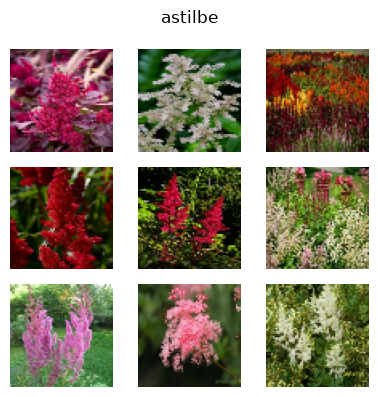

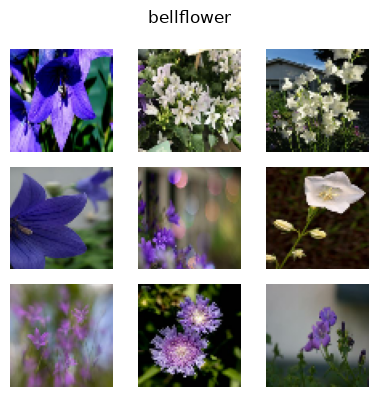

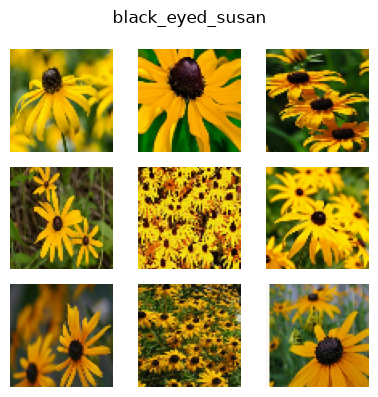

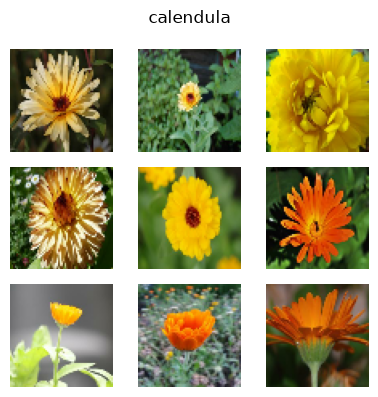

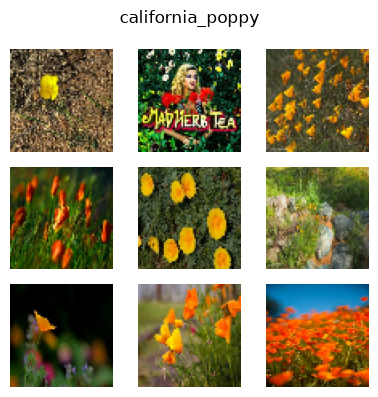

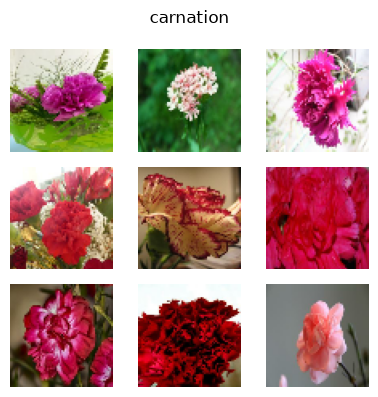

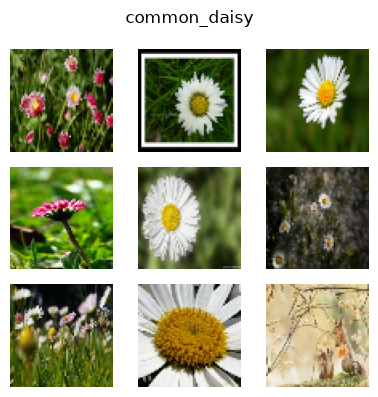

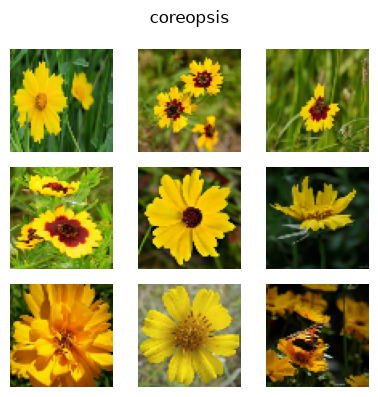

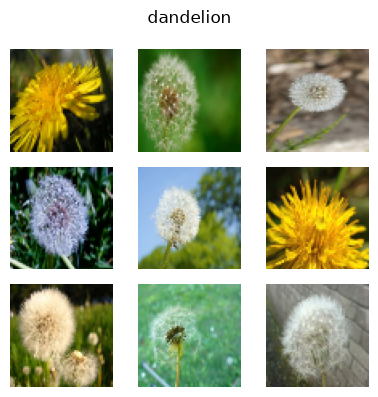

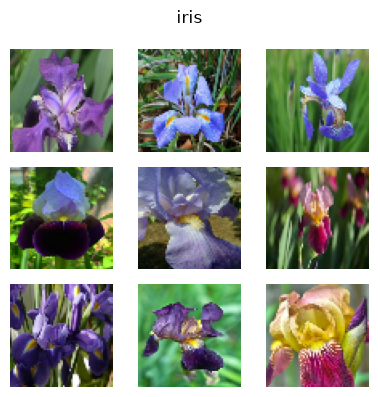

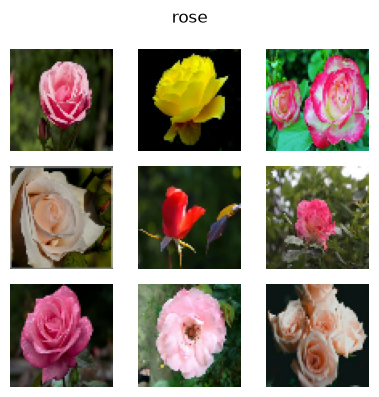

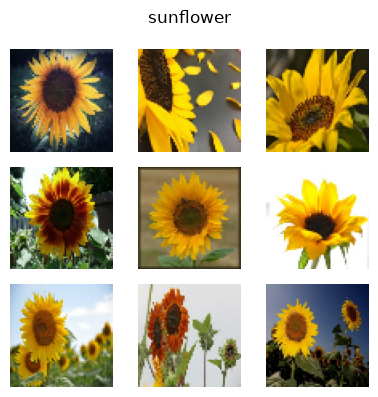

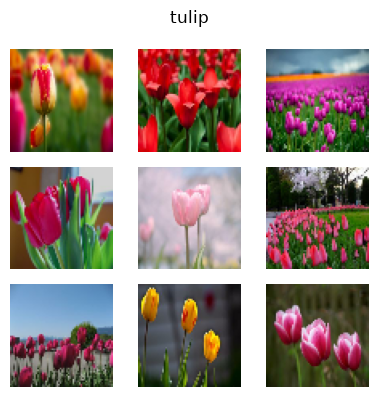

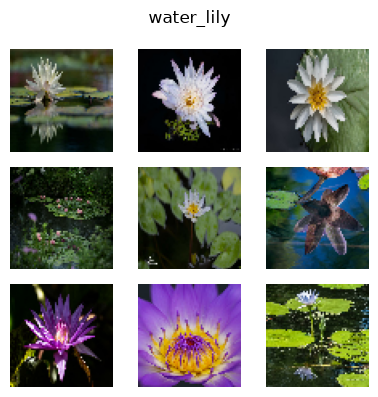

In [8]:
visualize_images(train_ds, class_names)

**To-Do (written):** Analyze expected challenges for classification in 4 to 6 sentences. Mention similar color palettes across species, intra class variation due to background and lighting, and class imbalance if present.

**My analysis:** the hardest part is that several species share the same colors. Black-eyed Susan, coreopsis, calendula, sunflower and dandelion are all yellow-orange flowers with a dark or yellow center, and at 64x64 the petal shape that separates them is mostly blurred away. Common daisy and water lily are both white star-shaped flowers, and rose, carnation and tulip can all be pink or red with layered petals. Inside each class there is a lot of variation: some photos are close-ups of one flower, others show a whole field (tulip, california poppy) or the plant with leaves (astilbe, iris), and the backgrounds and lighting change a lot. Some images even have frames or text on them. The class imbalance is small (726 vs 1,041 images), so I don't expect it to matter much, but astilbe has the fewest examples.

**Learning point**  
Vision models learn features from texture, color, and shape. Dataset bias and imbalance can dominate results without careful preprocessing and evaluation.


## Part 2. Model architecture design

**As stated in the exercises**  
Start from the provided model. Experiment with the number of convolutional layers, filters, kernel sizes, max pooling layers. Try different dense layers and dropout. Consider Batch Normalization. Justify your architectural choices.


**What this cell does (PREFILLED):** builds the baseline CNN: three Conv2D + MaxPooling2D blocks (32, 64, 128 filters), then Flatten, one Dense layer of 128 with Dropout 0.3, and a softmax output with 14 classes.

In [9]:
# PREFILLED: just execute — baseline model scaffold
from tensorflow.keras import models

def build_baseline(num_classes):
    model = models.Sequential([
        layers.Input(shape=(*IMG_SIZE, 3)),
        layers.Rescaling(1./255),  # safety if datasets were not normalized
        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),
        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),
        layers.Conv2D(128, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),
        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(num_classes, activation="softmax")
    ])
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

baseline = build_baseline(num_classes)
baseline.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,048,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 14)             │         1,806 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,143,758 (4.36 MB)

 Trainable params: 1,143,758 (4.36 MB)

 Non-trainable params: 0 (0.00 B)

**What this cell does:** builds my improved variant. I wrote it as a function with a few settings, so I can switch one thing at a time in the experiment below:
- 4 conv blocks with 32 → 64 → 128 → 256 filters (each block halves the image: 64 → 32 → 16 → 8 → 4)
- `BatchNormalization` after each Conv2D (and before the ReLU)
- the kernel size of the first layer (3x3 or 5x5)
- Dense 256 with Dropout 0.4

In [10]:
# To-Do: create an improved architecture variant
def build_variant(num_classes, first_kernel=3, use_bn=True, dropout=0.4):
    model = models.Sequential()
    model.add(layers.Input(shape=(*IMG_SIZE, 3)))
    model.add(layers.Rescaling(1./255))                 # pixels 0-255 -> 0-1
    for i, filters in enumerate([32, 64, 128, 256]):
        k = first_kernel if i == 0 else 3
        model.add(layers.Conv2D(filters, k, padding="same"))
        if use_bn:
            model.add(layers.BatchNormalization())      # keeps the activations in a stable range
        model.add(layers.Activation("relu"))
        model.add(layers.MaxPooling2D())                # halves height and width
    model.add(layers.Flatten())
    model.add(layers.Dense(256, activation="relu"))
    model.add(layers.Dropout(dropout))                  # switches off 40% of the neurons while training
    model.add(layers.Dense(num_classes, activation="softmax"))
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

model_variant = build_variant(num_classes)
model_variant.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 8, 8, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 8, 8, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │     1,048,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 14)             │         3,598 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,442,766 (5.50 MB)

 Trainable params: 1,441,806 (5.50 MB)

 Non-trainable params: 960 (3.75 KB)

**What this cell does:** trains 4 architectures with the same settings (Adam, learning rate 0.001, batch 32, at most 15 epochs) and compares them on the validation set:
1. the PREFILLED baseline
2. my variant (4 blocks + BatchNorm + Dropout 0.4)
3. the variant with a 5x5 kernel in the first layer
4. the variant without BatchNorm, to see what BatchNorm adds

`EarlyStopping` stops a run when the validation loss hasn't improved for 3 epochs and puts back the best weights. The validation set has only 98 images, so one image is about 1% accuracy and small gaps are noise.

In [11]:
# architecture experiments (same optimizer, batch size and epoch budget for all)
import time
import pandas as pd

arch_settings = {
    "baseline (3 conv, Dropout 0.3)": lambda: build_baseline(num_classes),
    "variant (4 conv + BN, Dropout 0.4)": lambda: build_variant(num_classes),
    "variant, 5x5 first kernel": lambda: build_variant(num_classes, first_kernel=5),
    "variant without BN": lambda: build_variant(num_classes, use_bn=False),
}

arch_rows, arch_hist = [], {}
for name, builder in arch_settings.items():
    tf.keras.utils.set_random_seed(SEED)
    m = builder()
    es = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
    t0 = time.time()
    h = m.fit(train_ds, validation_data=val_ds, epochs=15, callbacks=[es], verbose=0)
    val_loss, val_acc = m.evaluate(val_ds, verbose=0)    # accuracy of the restored best weights
    arch_hist[name] = h
    arch_rows.append({"architecture": name, "params": m.count_params(),
                      "epochs run": len(h.history["loss"]),
                      "train acc": round(h.history["accuracy"][-1], 3),
                      "val acc": round(val_acc, 3), "val loss": round(val_loss, 3),
                      "time (s)": round(time.time() - t0)})
    print(f"{name}: val acc {val_acc:.3f}, val loss {val_loss:.3f}")

arch_table = pd.DataFrame(arch_rows)
arch_table

/workspace/w5d3_xpdc/venv/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).


baseline (3 conv, Dropout 0.3): val acc 0.765, val loss 0.702


variant (4 conv + BN, Dropout 0.4): val acc 0.653, val loss 1.037


variant, 5x5 first kernel: val acc 0.643, val loss 0.990


variant without BN: val acc 0.724, val loss 0.765


,architecture,params,epochs run,train acc,val acc,val loss,time (s)
0,"baseline (3 conv, Dropout 0.3)",1143758,9,0.858,0.765,0.702,99
1,"variant (4 conv + BN, Dropout 0.4)",1442766,11,0.715,0.653,1.037,372
2,"variant, 5x5 first kernel",1444302,11,0.717,0.643,0.990,411
3,variant without BN,1440846,9,0.856,0.724,0.765,111


Architecture I keep for the next parts: baseline (3 conv, Dropout 0.3)


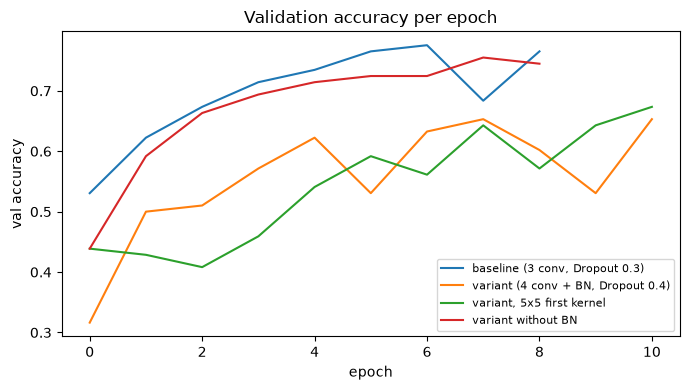

In [12]:
# pick the architecture with the best validation accuracy (lower val loss breaks a tie)
best_arch = arch_table.sort_values(["val acc", "val loss"], ascending=[False, True]).iloc[0]["architecture"]
build_best = arch_settings[best_arch]
print("Architecture I keep for the next parts:", best_arch)

plt.figure(figsize=(7, 4))
for name, h in arch_hist.items():
    plt.plot(h.history["val_accuracy"], label=name)
plt.title("Validation accuracy per epoch"); plt.xlabel("epoch"); plt.ylabel("val accuracy")
plt.legend(fontsize=8); plt.tight_layout(); plt.show()

**To-Do (written):** Justify your chosen layers and parameters in 4 to 6 sentences. Refer to receptive field growth, normalization stabilizing training, and dropout for regularization.

**My justification:** I expected my variant to win, but under the same budget the **PREFILLED baseline was the best (val acc 0.765, val loss 0.702)**, so I keep it for the next parts.
- Three conv blocks are enough for 64x64 images: after three 3x3 conv + 2x2 pooling steps, each neuron already sees a large part of the image, so a fourth block (8x8 → 4x4) adds parameters but not much new context.
- BatchNormalization is meant to stabilize training, but here both BN variants learned more slowly. Their training accuracy was only about 0.72 when EarlyStopping stopped them, against 0.86 for the models without BN, and their validation accuracy jumped around. With more epochs they might catch up, but not within 15 epochs on my CPU.
- The 5x5 first kernel gave no gain over 3x3 (0.643 vs 0.653), so small kernels stacked on top of each other are enough.
- Dropout 0.3 in the baseline was already enough. The baseline still overfits a bit (train 0.86 vs val 0.77), and that's what I try to fix with augmentation in Part 4.

## Part 3. Hyperparameter tuning

**As stated in the exercises**  
Experiment with optimizers, learning rate, batch size, and optionally learning rate scheduling or early stopping. Track experiments and results. Report the best combination.


**What this cell does (PREFILLED):** two helpers: `fit_model` trains a model and times it, and `plot_curves` draws the accuracy and loss curves.

In [13]:
# PREFILLED: just execute — utilities for training and plotting
import time

def fit_model(model, train_ds, val_ds, epochs=5, callbacks=None):
    t0 = time.time()
    history = model.fit(train_ds, validation_data=val_ds, epochs=epochs, callbacks=callbacks, verbose=2)
    dt = time.time() - t0
    return history, dt

def plot_curves(history, title="Training"):
    plt.figure(figsize=(6,4))
    plt.plot(history.history.get("accuracy", []), label="acc")
    plt.plot(history.history.get("val_accuracy", []), label="val_acc")
    plt.title(title); plt.xlabel("epoch"); plt.ylabel("accuracy"); plt.legend(); plt.tight_layout(); plt.show()
    plt.figure(figsize=(6,4))
    plt.plot(history.history.get("loss", []), label="loss")
    plt.plot(history.history.get("val_loss", []), label="val_loss")
    plt.title(title); plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend(); plt.tight_layout(); plt.show()

**What this cell does:** tries 3 optimizers, 2 learning rates and 2 batch sizes on the architecture I picked in Part 2. Every run gets the same two callbacks:
- `EarlyStopping` (patience 4 on the validation loss, best weights restored)
- `ReduceLROnPlateau`, which halves the learning rate when the validation loss stops improving for 2 epochs (my learning-rate schedule)

Each run has at most 15 epochs. To change the batch size I re-batch the cached dataset.

In [14]:
# To-Do: run a few experiments
opts = [
    ("adam", 1e-3, 32),
    ("adam", 5e-4, 32),
    ("adam", 1e-3, 64),
    ("rmsprop", 1e-3, 32),
    ("sgd", 1e-2, 64),
]
results, hp_models, hp_hist = [], {}, {}
for opt_name, lr, batch in opts:
    tf.keras.utils.set_random_seed(SEED)
    model = build_best()                                       # rebuild a fresh model each time
    if opt_name == "adam":
        optimizer = tf.keras.optimizers.Adam(lr)
    elif opt_name == "rmsprop":
        optimizer = tf.keras.optimizers.RMSprop(lr)
    else:
        optimizer = tf.keras.optimizers.SGD(lr, momentum=0.9, nesterov=True)
    model.compile(optimizer=optimizer, loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    cb = [tf.keras.callbacks.EarlyStopping(patience=4, restore_best_weights=True),
          tf.keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=2, verbose=0)]
    train_b = train_ds.unbatch().batch(batch).prefetch(AUTOTUNE)   # same images, new batch size
    hist, dur = fit_model(model, train_b, val_ds, epochs=15, callbacks=cb)
    val_loss, val_acc = model.evaluate(val_ds, verbose=0)
    key = f"{opt_name} lr={lr} batch={batch}"
    hp_models[key], hp_hist[key] = model, hist
    results.append({"run": key, "opt": opt_name, "lr": lr, "batch": batch,
                    "epochs run": len(hist.history["loss"]),
                    "best_val_acc": round(float(val_acc), 3), "val_loss": round(float(val_loss), 3),
                    "time_s": round(dur, 1)})

results_df = pd.DataFrame(results).sort_values(["best_val_acc", "val_loss"], ascending=[False, True])
results_df

Epoch 1/15


/workspace/w5d3_xpdc/venv/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).


427/427 - 8s - 19ms/step - accuracy: 0.3823 - loss: 1.7820 - val_accuracy: 0.5306 - val_loss: 1.3612 - learning_rate: 0.0010


Epoch 2/15


/workspace/w5d3_xpdc/venv/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.


427/427 - 5s - 13ms/step - accuracy: 0.5682 - loss: 1.2555 - val_accuracy: 0.6122 - val_loss: 1.0896 - learning_rate: 0.0010


... (115 outputs left out)

214/214 - 8s - 38ms/step - accuracy: 0.8468 - loss: 0.4348 - val_accuracy: 0.7143 - val_loss: 0.8704 - learning_rate: 0.0025


Epoch 13/15


214/214 - 7s - 34ms/step - accuracy: 0.8626 - loss: 0.3905 - val_accuracy: 0.6939 - val_loss: 0.9698 - learning_rate: 0.0025


,run,opt,lr,batch,epochs run,best_val_acc,val_loss,time_s
0,adam lr=0.001 batch=32,adam,0.0010,32,12,0.745,0.758,106.4
3,rmsprop lr=0.001 batch=32,rmsprop,0.0010,32,13,0.745,0.840,118.6
4,sgd lr=0.01 batch=64,sgd,0.0100,64,13,0.714,0.797,92.8
1,adam lr=0.0005 batch=32,adam,0.0005,32,12,0.704,0.788,125.0
2,adam lr=0.001 batch=64,adam,0.0010,64,11,0.694,0.829,359.3


Best combination: adam lr=0.001 batch=32 | val acc 0.745


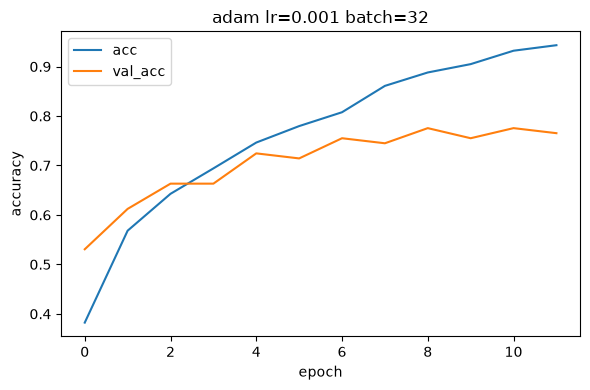

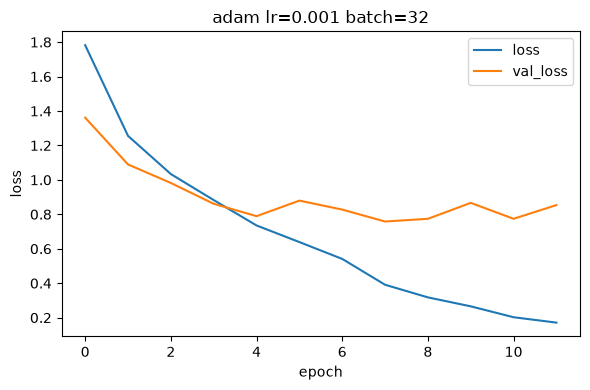

In [15]:
best_hp = results_df.iloc[0]
print("Best combination:", best_hp["run"], "| val acc", best_hp["best_val_acc"])
plot_curves(hp_hist[best_hp["run"]], title=best_hp["run"])

**To-Do (written):** Report the best hyperparameters you found and briefly explain why they might work well for this dataset.

**My result:** the best combination was **Adam, learning rate 0.001, batch size 32** (val acc 0.745, val loss 0.758). RMSprop with the same learning rate reached the same accuracy but a higher loss (0.840). SGD with momentum needed a 10x larger learning rate and was slower to start (0.714). The smaller Adam learning rate (0.0005) and the bigger batch (64) both ended a bit lower (0.704 and 0.694).

Adam works well here because it adapts the step size for every weight, so the default 0.001 trains fast without tuning. Batch 32 gives twice as many updates per epoch as 64, which helps when the number of epochs is limited. `ReduceLROnPlateau` halved the learning rate after the validation loss stalled, and `EarlyStopping` kept the weights from the best epoch (the validation loss was lowest around epoch 8 and then went up while training accuracy kept rising to 0.94). The gaps between the top runs are only 1 to 5 validation images, so I can't call them strong conclusions. I used one run per setting and at most 15 epochs to keep the CPU time reasonable. I didn't try another loss function: for one label per image, sparse categorical cross-entropy is the standard choice (categorical cross-entropy with one-hot labels gives the same thing).

## Part 4. Data augmentation

**As stated in the exercises**  
Implement data augmentation using `ImageDataGenerator`. Explore rotation, flipping, zooming, shifting, and shearing. Determine which augmentations help most and explain why.


**Guidance**  
Since we used `image_dataset_from_directory` above, you can either:  
Option A. Rebuild input using `ImageDataGenerator.flow_from_directory` on the training directory.  
Option B. Keep the tf.data pipeline and apply Keras preprocessing layers such as `RandomFlip`, `RandomRotation`.  
The exercises asks for `ImageDataGenerator`, so Option A shows that path.


**What this cell does:** prepares the `ImageDataGenerator` input. Two small changes from the hint above:
- I load the 64x64 training images once into a NumPy array and use `datagen.flow(...)`. It is the same `ImageDataGenerator`, but it doesn't re-read 13,642 JPEG files every epoch, which is much faster on a CPU.
- I don't use `rescale=1./255` in the generator, because my model already starts with a `Rescaling(1./255)` layer. Using both would divide the pixels by 255 twice.

I keep the provided `val` folder (`val_ds`, not augmented) as the validation set, so the results are comparable with Parts 2 and 3.

In [16]:
# To-Do: build an ImageDataGenerator pipeline (Option A)
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# training images as arrays (already resized to 64x64 by image_dataset_from_directory)
x_train = np.concatenate([x.numpy() for x, _ in train_ds])
y_train = np.concatenate([y.numpy() for _, y in train_ds])
print("x_train:", x_train.shape, "y_train:", y_train.shape)

def make_optimizer(name, lr):
    if name == "adam":
        return tf.keras.optimizers.Adam(lr)
    if name == "rmsprop":
        return tf.keras.optimizers.RMSprop(lr)
    return tf.keras.optimizers.SGD(lr, momentum=0.9, nesterov=True)

def train_with_generator(datagen, epochs, patience):
    # same architecture and best hyperparameters from Part 3, only the input changes
    tf.keras.utils.set_random_seed(SEED)
    model = build_best()
    model.compile(optimizer=make_optimizer(best_hp["opt"], best_hp["lr"]),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    flow = datagen.flow(x_train, y_train, batch_size=int(best_hp["batch"]), seed=SEED)
    cb = [tf.keras.callbacks.EarlyStopping(patience=patience, restore_best_weights=True),
          tf.keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=2, verbose=0)]
    hist = model.fit(flow, validation_data=val_ds, epochs=epochs, callbacks=cb, verbose=0)
    return model, hist

x_train: (13642, 64, 64, 3) y_train: (13642,)


**What this cell does:** tests each augmentation on its own, plus a run with no augmentation as the reference. All runs use the same model, optimizer and budget (at most 10 epochs).

In [17]:
# one augmentation at a time
aug_options = {
    "none": {},
    "rotation 30°": {"rotation_range": 30},
    "horizontal flip": {"horizontal_flip": True},
    "vertical flip": {"vertical_flip": True},
    "zoom 0.2": {"zoom_range": 0.2},
    "shift 0.15": {"width_shift_range": 0.15, "height_shift_range": 0.15},
    "shear 0.2": {"shear_range": 0.2},
}
aug_rows = []
for name, params in aug_options.items():
    datagen = ImageDataGenerator(fill_mode="nearest", **params)
    t0 = time.time()
    m, h = train_with_generator(datagen, epochs=10, patience=4)
    val_loss, val_acc = m.evaluate(val_ds, verbose=0)
    aug_rows.append({"augmentation": name, "epochs run": len(h.history["loss"]),
                     "train acc": round(h.history["accuracy"][-1], 3),
                     "val acc": round(val_acc, 3), "val loss": round(val_loss, 3),
                     "time (s)": round(time.time() - t0)})
    print(f"{name}: val acc {val_acc:.3f}, val loss {val_loss:.3f}")

aug_table = pd.DataFrame(aug_rows)
aug_table

none: val acc 0.755, val loss 0.728


rotation 30°: val acc 0.796, val loss 0.672


horizontal flip: val acc 0.796, val loss 0.565


vertical flip: val acc 0.765, val loss 0.665


zoom 0.2: val acc 0.735, val loss 0.726


shift 0.15: val acc 0.765, val loss 0.664


shear 0.2: val acc 0.755, val loss 0.665


,augmentation,epochs run,train acc,val acc,val loss,time (s)
0,none,10,0.914,0.755,0.728,344
1,rotation 30°,10,0.796,0.796,0.672,98
2,horizontal flip,10,0.818,0.796,0.565,60
3,vertical flip,10,0.796,0.765,0.665,57
4,zoom 0.2,10,0.803,0.735,0.726,65
5,shift 0.15,10,0.752,0.765,0.664,65
6,shear 0.2,10,0.927,0.755,0.665,179


**What this cell does:** combines the augmentations that did at least as well as "none" on validation loss into one generator, and trains that model longer (at most 30 epochs, `EarlyStopping` patience 6). I compare on the loss because it changes more smoothly than accuracy on 98 images. If none of them helps, I fall back to the template's mix.

Augmentations I combine: ['rotation 30°', 'horizontal flip', 'vertical flip', 'zoom 0.2', 'shift 0.15', 'shear 0.2']
{'rotation_range': 30, 'horizontal_flip': True, 'vertical_flip': True, 'zoom_range': 0.2, 'width_shift_range': 0.15, 'height_shift_range': 0.15, 'shear_range': 0.2}


Augmented model: val acc 0.735, val loss 0.714, 23 epochs, 3.8 min


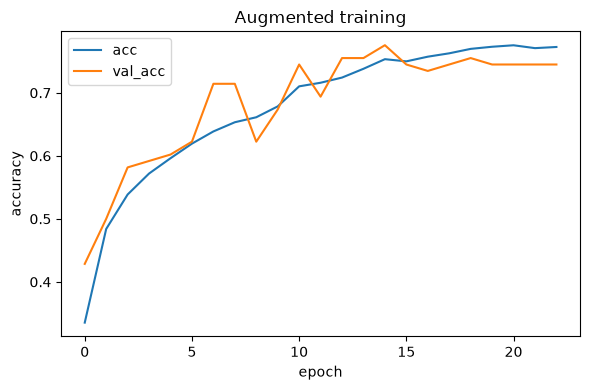

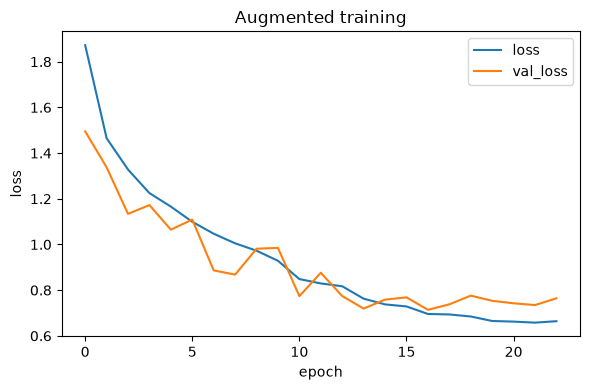

In [18]:
# combine the helpful augmentations and train the final augmented model
none_loss = aug_table.loc[aug_table["augmentation"] == "none", "val loss"].item()
helpful = [r["augmentation"] for _, r in aug_table.iterrows()
           if r["augmentation"] != "none" and r["val loss"] <= none_loss]
if not helpful:
    helpful = ["rotation 30°", "horizontal flip", "zoom 0.2", "shift 0.15", "shear 0.2"]
combo = {}
for name in helpful:
    combo.update(aug_options[name])
print("Augmentations I combine:", helpful)
print(combo)

datagen = ImageDataGenerator(fill_mode="nearest", **combo)
t0 = time.time()
model_aug, hist_aug = train_with_generator(datagen, epochs=30, patience=6)
aug_time = time.time() - t0
aug_val_loss, aug_val_acc = model_aug.evaluate(val_ds, verbose=0)
print(f"Augmented model: val acc {aug_val_acc:.3f}, val loss {aug_val_loss:.3f}, "
      f"{len(hist_aug.history['loss'])} epochs, {aug_time/60:.1f} min")
plot_curves(hist_aug, title="Augmented training")

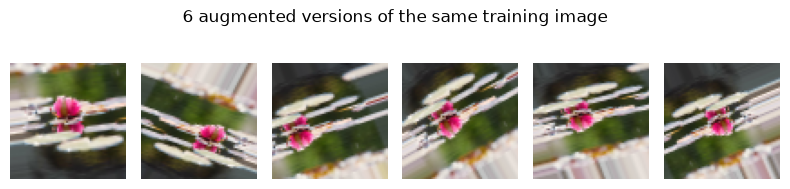

In [19]:
# show what the combined augmentation does to one image
sample = x_train[:1]
plt.figure(figsize=(8, 2))
for i, batch in enumerate(datagen.flow(sample, batch_size=1, seed=SEED)):
    plt.subplot(1, 6, i + 1)
    plt.imshow(batch[0].astype("uint8")); plt.axis("off")
    if i == 5:
        break
plt.suptitle("6 augmented versions of the same training image"); plt.tight_layout(); plt.show()

**My analysis:**
- Every single augmentation except zoom matched or beat "none" on validation loss (0.728). The clear winners were **horizontal flip (val acc 0.796, val loss 0.565)** and **rotation 30° (0.796, 0.672)**. These were the best validation accuracies in the whole notebook. A flower photographed from the left or the right, or tilted, is still the same species, so these transforms add realistic new examples. They also don't change the colors or petal shapes the model relies on.
- Vertical flip, shift and shear helped a little on the loss (about 0.665) but not on accuracy. Zoom 0.2 didn't help (0.735), probably because zooming in at 64x64 crops away part of the flower and blurs it further.
- Without augmentation the training accuracy reached 0.914 against 0.755 on validation. With one augmentation the training accuracy stayed near 0.80, which is a much smaller gap and less memorizing.
- Combining all six (my rule picked every augmentation with loss ≤ 0.728, and zoom just passed with 0.726) made the task too hard for the budget. After 23 epochs the training accuracy was only about 0.77, and the validation accuracy (0.735) was lower than with one flip alone. That model was underfitting. It needs many more epochs, or a milder mix such as only horizontal flip + rotation. If I train it again, horizontal flip + rotation is the mix I would use.

**Learning point**  
Augmentation encodes invariances like rotation and translation. It increases effective sample diversity which often reduces overfitting.


## Part 5. Performance evaluation and analysis

**As stated in the exercises**  
Plot training and validation curves. Compute precision, recall, F1, and a confusion matrix. Visualize predictions on a test set and analyze misclassifications.


**What this cell does (PREFILLED):** `collect_preds` runs the model over a dataset and returns the true labels, the predicted labels and the probabilities. `plot_confusion` draws the confusion matrix.

In [20]:
# PREFILLED: just execute — helpers for evaluation on a dataset
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

def collect_preds(model, ds):
    y_true = []
    y_prob = []
    for xb, yb in ds:
        pr = model.predict(xb, verbose=0)
        y_prob.append(pr)
        y_true.append(yb.numpy())
    y_true = np.concatenate(y_true)
    y_prob = np.concatenate(y_prob)
    if y_prob.ndim == 2 and y_prob.shape[1] > 1:
        y_pred = y_prob.argmax(axis=1)
    else:
        y_pred = (y_prob.ravel() >= 0.5).astype(int)
    return y_true, y_pred, y_prob

def plot_confusion(cm, labels):
    plt.figure(figsize=(6,6))
    plt.imshow(cm)
    plt.title("Confusion matrix")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    ticks = np.arange(len(labels))
    plt.xticks(ticks, labels, rotation=90)
    plt.yticks(ticks, labels)
    plt.tight_layout()
    plt.show()

**What this cell does:** picks my final model (the augmented model or the best Part 3 model, whichever has the higher validation accuracy), plots its curves, and prints the precision, recall and F1 for every class plus the confusion matrix.

Final model: best Part 3 model (no augmentation) | val acc 0.745


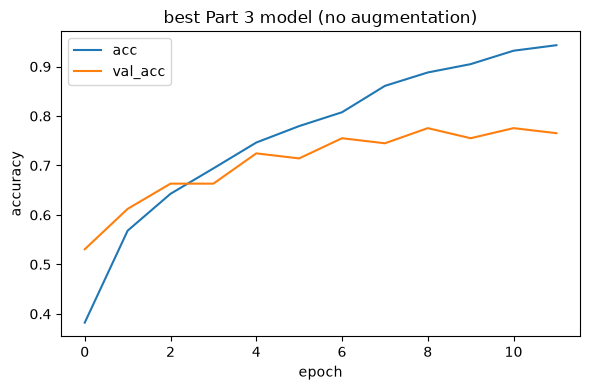

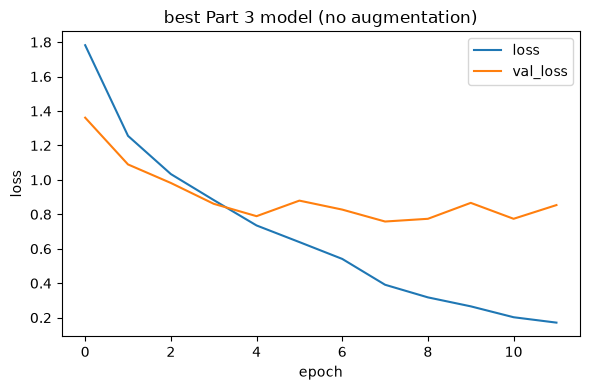

                  precision    recall  f1-score   support

         astilbe      0.800     0.571     0.667         7
      bellflower      0.750     0.857     0.800         7
black_eyed_susan      1.000     0.571     0.727         7
       calendula      0.500     0.429     0.462         7
california_poppy      0.667     0.857     0.750         7
       carnation      0.667     0.857     0.750         7
    common_daisy      0.600     0.429     0.500         7
       coreopsis      0.700     1.000     0.824         7
       dandelion      0.875     1.000     0.933         7
            iris      0.778     1.000     0.875         7
            rose      0.714     0.714     0.714         7
       sunflower      1.000     0.714     0.833         7
           tulip      0.833     0.714     0.769         7
      water_lily      0.714     0.714     0.714         7

        accuracy                          0.745        98
       macro avg      0.757     0.745     0.737        98
    weighted

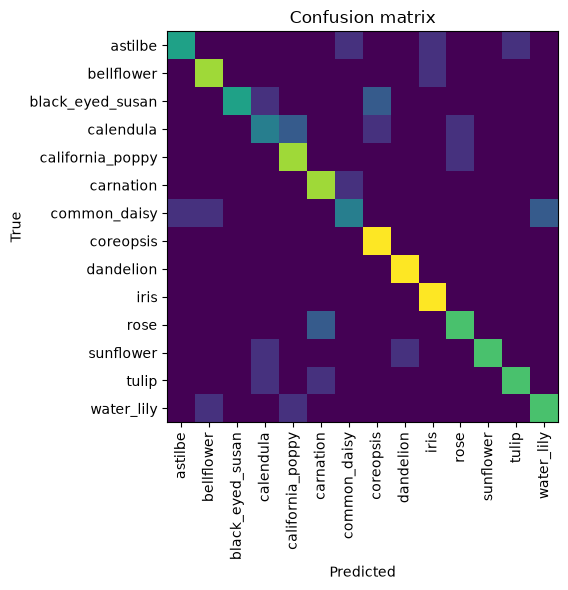

In [21]:
# To-Do: evaluate your best model on val_ds
hp_best_model = hp_models[best_hp["run"]]
hp_val_loss, hp_val_acc = hp_best_model.evaluate(val_ds, verbose=0)
if aug_val_acc >= hp_val_acc:
    best_model, best_hist, best_name = model_aug, hist_aug, "augmented model"
else:
    best_model, best_hist, best_name = hp_best_model, hp_hist[best_hp["run"]], "best Part 3 model (no augmentation)"
print(f"Final model: {best_name} | val acc {max(aug_val_acc, hp_val_acc):.3f}")
plot_curves(best_hist, title=best_name)

y_true, y_pred, y_prob = collect_preds(best_model, val_ds)
print(classification_report(y_true, y_pred, target_names=class_names, digits=3, zero_division=0))
cm = confusion_matrix(y_true, y_pred)
plot_confusion(cm, class_names)

In [22]:
# which classes are hardest, and which pairs get mixed up
from sklearn.metrics import f1_score
f1s = f1_score(y_true, y_pred, average=None, zero_division=0)
per_class = pd.DataFrame({"class": class_names, "val images": cm.sum(axis=1),
                          "correct": np.diag(cm), "f1": f1s.round(3)}).sort_values("f1")
print(per_class.to_string(index=False))

pairs = [(class_names[i], class_names[j], cm[i, j]) for i in range(num_classes)
         for j in range(num_classes) if i != j and cm[i, j] > 0]
print("\nMistakes (true -> predicted : count):")
for t, p, n in sorted(pairs, key=lambda x: -x[2]):
    print(f"  {t} -> {p} : {n}")

# training accuracy of the same model, to measure the gap
train_loss, train_acc = best_model.evaluate(train_ds, verbose=0)
print(f"\nTrain acc {train_acc:.3f} vs val acc {(y_true == y_pred).mean():.3f}")

           class  val images  correct    f1
       calendula           7        3 0.462
    common_daisy           7        3 0.500
         astilbe           7        4 0.667
            rose           7        5 0.714
      water_lily           7        5 0.714
black_eyed_susan           7        4 0.727
       carnation           7        6 0.750
california_poppy           7        6 0.750
           tulip           7        5 0.769
      bellflower           7        6 0.800
       coreopsis           7        7 0.824
       sunflower           7        5 0.833
            iris           7        7 0.875
       dandelion           7        7 0.933

Mistakes (true -> predicted : count):
  black_eyed_susan -> coreopsis : 2
  calendula -> california_poppy : 2
  common_daisy -> water_lily : 2
  rose -> carnation : 2
  astilbe -> common_daisy : 1
  astilbe -> iris : 1
  astilbe -> tulip : 1
  bellflower -> iris : 1
  black_eyed_susan -> calendula : 1
  calendula -> coreopsis : 1
  calen


Train acc 0.916 vs val acc 0.745


**What this cell does:** shows 12 validation images with the true and predicted class (green = correct, red = wrong), and then every misclassified validation image.

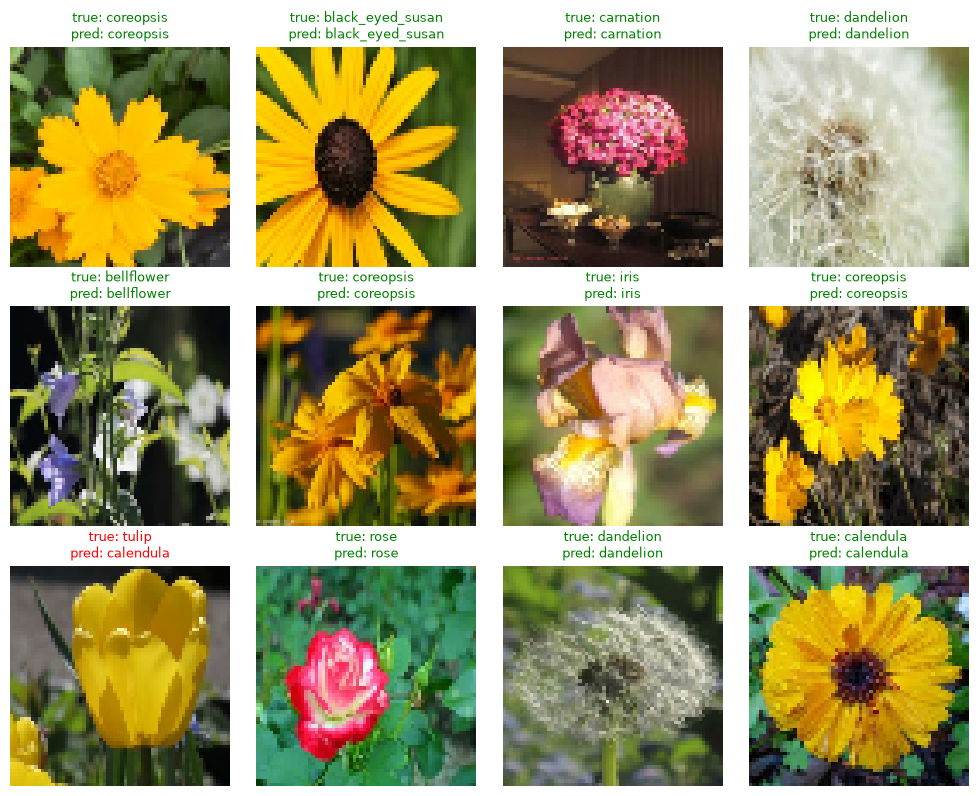

25 misclassified out of 98


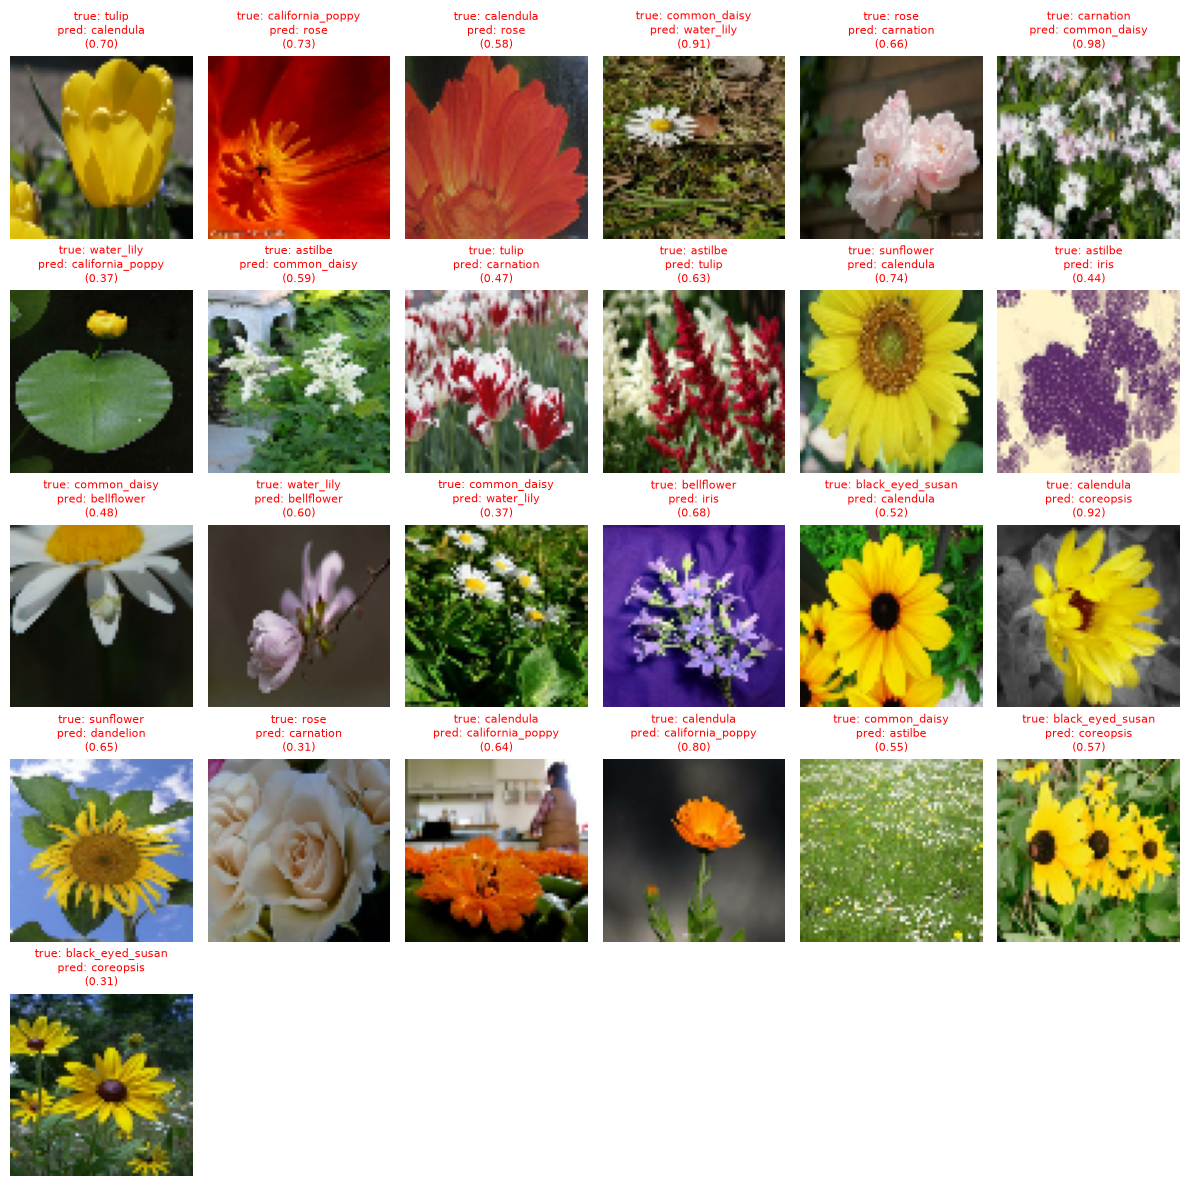

In [23]:
# To-Do: visualize a few predictions and inspect errors
val_imgs = np.concatenate([x.numpy() for x, _ in val_ds])   # same order as y_true / y_pred

take = 12
plt.figure(figsize=(10, 8))
for i in range(take):
    plt.subplot(3, 4, i + 1)
    plt.imshow(val_imgs[i].astype("uint8"))
    color = "green" if y_true[i] == y_pred[i] else "red"
    plt.title(f"true: {class_names[y_true[i]]}\npred: {class_names[y_pred[i]]}", color=color, fontsize=9)
    plt.axis("off")
plt.tight_layout(); plt.show()

wrong = np.where(y_true != y_pred)[0]
print(len(wrong), "misclassified out of", len(y_true))
cols = 6
rows = int(np.ceil(len(wrong) / cols))
plt.figure(figsize=(12, 2.4 * rows))
for k, i in enumerate(wrong):
    plt.subplot(rows, cols, k + 1)
    plt.imshow(val_imgs[i].astype("uint8"))
    plt.title(f"true: {class_names[y_true[i]]}\npred: {class_names[y_pred[i]]}\n({y_prob[i].max():.2f})", color="red", fontsize=8)
    plt.axis("off")
plt.tight_layout(); plt.show()

**To-Do (written):** Identify classes that your model finds difficult. Explain possible causes such as similar morphology or color, or small sample counts.

**My analysis:** my final model is the best Part 3 model (Adam 0.001, batch 32, no augmentation). It was chosen because it beat the combined-augmentation model (0.745 vs 0.735). It gets **73 of 98 validation images right (accuracy 0.745, macro F1 0.737)**.
- **Curves:** the training accuracy keeps going up (0.916 on the whole training set) while the validation loss stops improving after about 8 epochs, so the model is **overfitting**. EarlyStopping limits the damage by restoring the best epoch.
- **Hardest classes:** **calendula (F1 0.46)** and **common daisy (F1 0.50)**, then astilbe (0.67). The easiest were dandelion (0.93), iris (0.88) and coreopsis (0.82).
- **Why:** the mistakes follow color more than shape. Calendula is confused with california poppy (2) and coreopsis, which are also orange or yellow. Black-eyed Susan → coreopsis (2) are both yellow with dark centers. Rose → carnation (2) are pink layered petals. Common daisy → water lily (2) are white star-shaped flowers. In the grid of mistakes, several wrong images are wide shots (a daisy meadow, a tulip field), close crops that only show petals (calendula, poppy), or flowers with a gray or black background. At 64x64 the shape details are lost, so the model falls back on the dominant color.
- **Caveat:** with only 7 validation images per class, one image changes a class's recall by 14 points. So the ranking of hard classes is a hint, not a precise measurement.

## Part 6. Model saving and deployment (optional)

**As stated in the exercises**  
Save your trained model in `.h5` or SavedModel format. Optionally consider web or cloud deployment.


**What this cell does:** saves the final model in the native Keras format (`.keras`) and loads it back to check that it gives the same accuracy. In Keras 3, `model.save()` takes `.keras` or `.h5`; a SavedModel folder for serving is made with `model.export()` instead.

In [24]:
# To-Do: save your best model
best_model.save("./data/flower_cnn.keras")
print("Saved to ./data/flower_cnn.keras", round(os.path.getsize("./data/flower_cnn.keras") / 1e6, 1), "MB")

# load it back and check that it gives the same validation accuracy
loaded = tf.keras.models.load_model("./data/flower_cnn.keras")
print("Reloaded model val acc:", round(loaded.evaluate(val_ds, verbose=0)[1], 3))

Saved to ./data/flower_cnn.keras 13.8 MB


Reloaded model val acc: 0.745


**Deployment (optional), short note:** to serve this model I would load `flower_cnn.keras` once in a small Flask or FastAPI app. The endpoint resizes the uploaded photo to 64x64 and returns the top class with its probability. The same app could run on Google Cloud Run or a Hugging Face Space. I didn't build this part.

## Conclusion
- I loaded the 14-class flower dataset with `image_dataset_from_directory` at 64x64. The classes are fairly balanced (726 to 1,041 training images each), but the validation set has only 98 images.
- In my architecture tests the PREFILLED 3-block baseline beat my deeper BatchNorm variants within 15 epochs (val acc 0.765 vs 0.653).
- The best hyperparameters were Adam, learning rate 0.001, batch 32, with EarlyStopping and ReduceLROnPlateau (val acc 0.745).
- Single augmentations helped most: horizontal flip and rotation each reached **0.796 validation accuracy**, the best in the notebook. Combining all six underfit within 23 epochs (0.735).
- My saved final model has 0.745 validation accuracy. Calendula and common daisy are the hardest classes, and most mistakes are between flowers with similar colors.
- Everything ran on a CPU with modest epochs (whole notebook about 50 minutes). With a GPU I would train the flip + rotation model longer and try a larger image size.